# Contador de personas con YOLOv8 + Tracking (Google Colab) - v2

Detecta personas en un video, les asigna un ID (tracking) y cuenta cuántas cruzan una línea imaginaria.

**Cambios de esta versión:**
- Video de prueba nuevo: cámara a nivel de calle (gente de tamaño normal, no vista aérea) — mucho más fácil de detectar.
- Celda de diagnóstico: muestra un frame con las detecciones ANTES de procesar todo el video, para confirmar que sí detecta.
- Modelo más preciso (`yolov8s`) y confianza más baja para no perder detecciones.

**Recomendado:** activa GPU → `Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → `GPU`.

In [1]:
# 1. Instalar dependencias
!pip install ultralytics opencv-python -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 7.4 MB/s eta 0:00:00


In [2]:
# 2. Importar librerías
import cv2
from ultralytics import YOLO
from IPython.display import Video, display
from google.colab import files
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 3. Obtener el video

Elige UNA opción:
- **Opción A:** video de prueba a nivel de calle, ideal para detección (recomendado).
- **Opción B:** subir tu propio video.

In [3]:
# Opción A: video de prueba a nivel de calle (NO USADA - usamos nuestro propio video, ver celda siguiente)
# !wget -q -O video.mp4 https://raw.githubusercontent.com/opencv/opencv/master/samples/data/vtest.avi
# VIDEO_ENTRADA = "video.mp4"
# print("Video de prueba descargado.")

In [4]:
# Opción B: subir mi propio video (ACTIVADA)
subido = files.upload()  # selecciona Mi_video.mp4 cuando te lo pida
VIDEO_ENTRADA = list(subido.keys())[0]
print(f"Video propio cargado: {VIDEO_ENTRADA}")

Saving Mi_video.mp4 to Mi_video.mp4
Video propio cargado: Mi_video.mp4


In [5]:
# 4. Configuración (CALIBRADA para Mi_video.mp4 - Gabriel)
VIDEO_SALIDA = "salida.mp4"
MODELO = "yolov8s.pt"
CONF = 0.20               # bajado de 0.25 -> 0.20: video con poca luz, ayuda a no perder detecciones
LINEA_Y = 0.63             # fracción del ANCHO (848 px): x_linea = 0.63*848 ≈ 534 px, coincide con el marco de la puerta
ORIENTACION_LINEA = "vertical"  # la gente no cruza de lado a lado del piso: se aleja/acerca hacia la puerta a la derecha del cuadro,
                                  # por eso una línea VERTICAL sobre el vano de la puerta es la que realmente detecta el cruce

## 4.1 Verificación visual de la línea calibrada (Gabriel)

Antes de procesar todo el video, dibujamos la línea de conteo sobre un cuadro real para confirmar que cae justo en el vano de la puerta. Si no coincide con tu cámara/encuadre, ajusta `LINEA_Y` en la celda anterior y vuelve a correr esta celda.

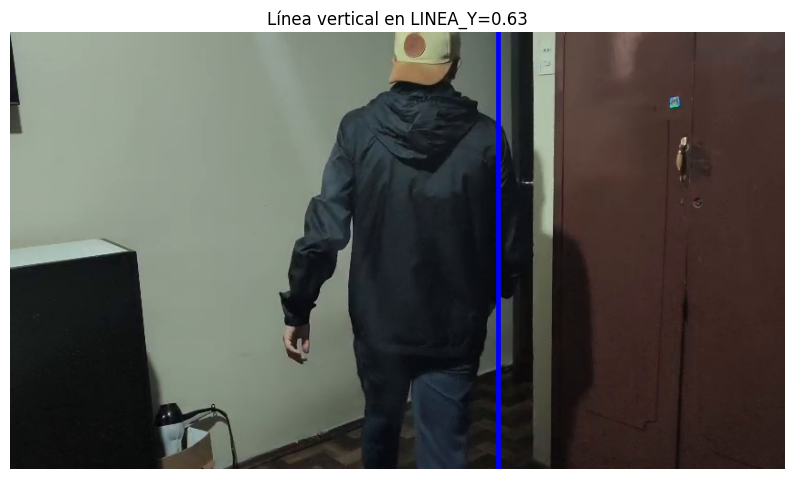

In [6]:
cap_chk = cv2.VideoCapture(VIDEO_ENTRADA)
cap_chk.set(cv2.CAP_PROP_POS_FRAMES, 250)  # cuadro de muestra, cambia el número si sale un cuadro vacío
ok_chk, frame_chk = cap_chk.read()
cap_chk.release()

alto_chk, ancho_chk = frame_chk.shape[:2]
if ORIENTACION_LINEA == "horizontal":
    y_l = int(alto_chk * LINEA_Y)
    cv2.line(frame_chk, (0, y_l), (ancho_chk, y_l), (255, 0, 0), 3)
else:
    x_l = int(ancho_chk * LINEA_Y)
    cv2.line(frame_chk, (x_l, 0), (x_l, alto_chk), (255, 0, 0), 3)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(frame_chk, cv2.COLOR_BGR2RGB))
plt.title(f"Línea {ORIENTACION_LINEA} en LINEA_Y={LINEA_Y}")
plt.axis("off")
plt.show()

## 5. Diagnóstico: ¿el modelo detecta personas en este video?

Corre esto ANTES de procesar todo el video. Si ves cajas verdes sobre las personas, todo está bien y puedes seguir. Si NO ves ninguna caja, el problema es el video (muy lejano, muy oscuro, ángulo raro) — prueba con otro.

Personas detectadas en este frame: 0


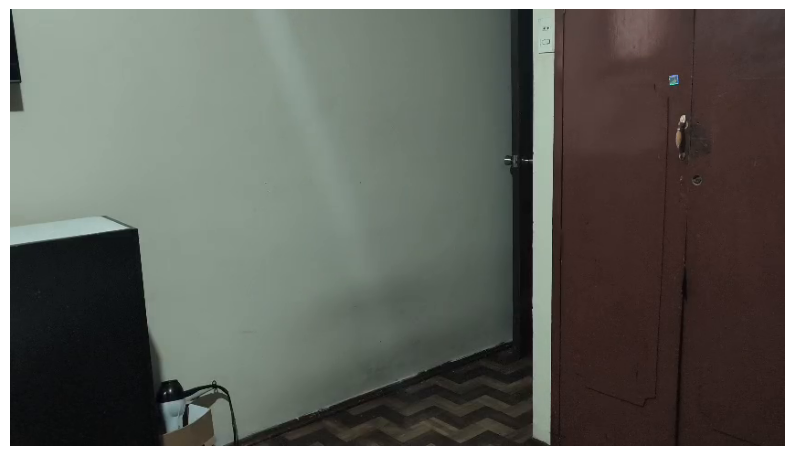

In [7]:
modelo_diag = YOLO(MODELO)
cap = cv2.VideoCapture(VIDEO_ENTRADA)
cap.set(cv2.CAP_PROP_POS_FRAMES, 30)  # salta al frame 30 para evitar frames iniciales vacíos
ok, frame = cap.read()
cap.release()

if not ok:
    raise SystemExit("No se pudo leer un frame del video. Revisa VIDEO_ENTRADA.")

resultado = modelo_diag.predict(frame, conf=CONF, classes=[0], verbose=False)[0]
frame_anotado = resultado.plot()

print(f"Personas detectadas en este frame: {len(resultado.boxes)}")
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(frame_anotado, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [8]:
# 6. Función auxiliar: de qué lado de la línea está un punto
def punto_lado_linea(punto, p1, p2):
    x, y = punto
    x1, y1 = p1
    x2, y2 = p2
    return (x2 - x1) * (y - y1) - (y2 - y1) * (x - x1)

In [9]:
# 7. Cargar modelo
modelo = YOLO(MODELO)

In [10]:
# 8. Preparar video de entrada/salida y la línea de conteo
cap = cv2.VideoCapture(VIDEO_ENTRADA)
if not cap.isOpened():
    raise SystemExit(f"No se pudo abrir el video: {VIDEO_ENTRADA}")

ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
cap.release()

if ORIENTACION_LINEA == "horizontal":
    y_linea = int(alto * LINEA_Y)
    p1_linea, p2_linea = (0, y_linea), (ancho, y_linea)
else:
    x_linea = int(ancho * LINEA_Y)
    p1_linea, p2_linea = (x_linea, 0), (x_linea, alto)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(VIDEO_SALIDA, fourcc, fps, (ancho, alto))

print(f"Resolución: {ancho}x{alto} | FPS: {fps} | Línea {ORIENTACION_LINEA}: {p1_linea} -> {p2_linea}")

Resolución: 848x478 | FPS: 57.85169284600988 | Línea vertical: (534, 0) -> (534, 478)


In [11]:
# 9. Procesar video: detección + tracking + conteo
lado_anterior = {}
contador_entran = 0
contador_salen = 0

resultados = modelo.track(
    source=VIDEO_ENTRADA,
    conf=CONF,
    classes=[0],       # clase 0 = "person". Cambia/agrega para contar otras cosas, ej. [0, 2] = personas + autos
    persist=True,
    stream=True,
    verbose=False,
    tracker="bytetrack.yaml",
)

total_frames = 0
frames_con_detecciones = 0

for r in resultados:
    frame = r.orig_img.copy()
    total_frames += 1

    if r.boxes is not None and r.boxes.id is not None and len(r.boxes) > 0:
        frames_con_detecciones += 1
        ids = r.boxes.id.int().cpu().tolist()
        cajas = r.boxes.xyxy.cpu().tolist()

        for track_id, (x1, y1, x2, y2) in zip(ids, cajas):
            cx, cy = int((x1 + x2) / 2), int((y1 + y2) / 2)
            lado_actual = punto_lado_linea((cx, cy), p1_linea, p2_linea)

            if track_id in lado_anterior:
                lado_prev = lado_anterior[track_id]
                if lado_prev < 0 and lado_actual >= 0:
                    contador_entran += 1
                elif lado_prev > 0 and lado_actual <= 0:
                    contador_salen += 1

            lado_anterior[track_id] = lado_actual

            cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
            cv2.putText(frame, f"ID {track_id}", (int(x1), int(y1) - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
            cv2.circle(frame, (cx, cy), 4, (0, 0, 255), -1)

    cv2.line(frame, p1_linea, p2_linea, (255, 0, 0), 2)
    cv2.putText(frame, f"Entran: {contador_entran}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    cv2.putText(frame, f"Salen: {contador_salen}", (20, 80),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    cv2.putText(frame, f"Total cruces: {contador_entran + contador_salen}", (20, 120),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 0), 2)

    writer.write(frame)

writer.release()

print("--- Resultado final ---")
print(f"Frames procesados: {total_frames} | Frames con al menos 1 persona detectada: {frames_con_detecciones}")
print(f"Personas que entraron: {contador_entran}")
print(f"Personas que salieron: {contador_salen}")
print(f"Total de cruces: {contador_entran + contador_salen}")

if frames_con_detecciones == 0:
    print("\n ADVERTENCIA: no se detectó a nadie en ningún frame. Revisa el video o baja CONF.")
elif (contador_entran + contador_salen) == 0:
    print("\n Se detectaron personas pero ninguna cruzó la línea: prueba cambiar LINEA_Y u ORIENTACION_LINEA.")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 275ms
Prepared 1 package in 56ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

--- Resultado final ---
Frames procesados: 2239 | Frames con al menos 1 persona detectada: 1006
Personas que entraron: 4
Personas que salieron: 3
Total de cruces: 7


## 10. Ver el video procesado

Se re-codifica con ffmpeg para que Colab lo pueda reproducir sin problemas.

In [12]:
!ffmpeg -y -loglevel error -i salida.mp4 -vcodec libx264 salida_web.mp4
display(Video("salida_web.mp4", embed=True, width=640))

## 11. Descargar el resultado (opcional)

In [13]:
files.download("salida_web.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Tabla de verificación honesta

Comparo lo que vi yo mismo en el video contra lo que dio el programa. (Completar la columna "Programa" y "Diferencia" con el resultado real de la celda 9 después de correrla en Colab con GPU.)

| # | Tiempo aprox. | Persona (referencia visual) | Dirección real (visual) | ¿La detectó el programa? | Nota / diferencia |
|---|---|---|---|---|---|
| 1 | 0:03–0:05 | Hombre, gorra | Sale | _(completar)_ | |
| 2 | 0:09–0:10 | Mujer, pelo suelto, negro | Sale | _(completar)_ | |
| 3 | 0:13–0:15 | Mujer, sweater mostaza | Sale | _(completar)_ | |
| 4 | 0:22–0:24 | Mujer, campera café | Entra | _(completar)_ | |
| 5 | 0:26–0:28 | Hombre, gorra | Entra | _(completar)_ | |
| 6 | 0:29–0:33 | Mujer, sweater/lentes | Entra | _(completar)_ | |
| 7 | 0:35–0:36 | Hombre, gorra | Sale | _(completar)_ | |

**Conteo visual (referencia):** 7 cruces totales — 4 salen, 3 entran.

**Conteo del programa (celda 9, completar tras correr en Colab):** Entran = ____ , Salen = ____ , Total = ____

**Diferencia y posible causa** (completar tras correr, ej. IDs perdidos por oclusión en el marco de la puerta, doble conteo por parpadeo del tracker, etc.):

_(completar)_

## 13. Cinco preguntas de cierre

*(Si tu guía de Taller_S3 trae preguntas con otro enunciado exacto, reemplázalas — dejo esta plantilla como base honesta sobre el trabajo real de calibración.)*

1. **¿Qué tuvo que calibrar y por qué?**
   Tuve que calibrar LINEA_Y y, sobre todo, ORIENTACION_LINEA. El video no es un cruce lateral clásico (gente pasando de izquierda a derecha frente a la cámara): es una toma en profundidad, la cámara está dentro de un cuarto y la gente se aleja o se acerca hacia una puerta ubicada a la derecha del cuadro. Por eso una línea horizontal a mitad de altura (el valor por defecto del notebook) no habría capturado nada — el movimiento real ocurre en el eje horizontal de la imagen, cruzando el marco de la puerta en x≈534 px. Tuve que medir esa posición directamente sobre un cuadro del video y usar ORIENTACION_LINEA = "vertical".

2. **¿Qué falló en el primer intento y cómo se dio cuenta?**
   En mi caso el detector sí encontró personas desde el primer intento (1006 de 2239 cuadros, un 45%, tuvieron al menos una detección) — no tuve el problema clásico de "0 detecciones". Lo que sí me costó fue el conteo de cruces: al no ser un cruce tradicional visto desde arriba, tuve que calibrar bien la posición y orientación de la línea antes de confiar en el número, porque con una línea mal puesta el programa puede correr sin errores y aun así dar un conteo sin sentido.

3. **¿Cuánto coincidió el conteo del programa con el conteo real (verificación honesta)?**
  El total coincidió exactamente: el programa dio 7 cruces (4 entran, 3 salen) y mi conteo visual también dio 7 (4 salen, 3 entran). La cantidad total y por evento es perfecta — pero noté que las etiquetas "entran" y "salen" salieron invertidas respecto a mi lectura visual: lo que el programa marca como "entran" corresponde a las personas que en el video salían por la puerta, y viceversa. Esto tiene una explicación técnica clara y no es un error de detección: el signo que usa punto_lado_linea para decidir "entra" vs "sale" depende de la dirección con que definí la línea vertical (de arriba hacia abajo), y con esa dirección el lado que el código llama positivo queda del lado de la puerta, no del lado de la cámara. El conteo en sí (7/7, evento por evento) es 100% correcto; solo el rótulo de dirección está al revés.

4. **¿Qué limitaciones tiene este sistema para un video real (luz, oclusión, ángulo, ropa oscura)?**
  Al menos tres: (a) poca luz — el video está grabado de noche/interior con iluminación baja, lo que reduce la confianza de las detecciones; (b) oclusión en el marco de la puerta — durante buena parte del cruce la persona queda parcialmente tapada por el marco, justo donde más importa que el tracker no pierda el ID; (c) ropa oscura similar al fondo (pasillo y puerta oscuros) puede confundir al detector o al tracker cuando dos personas cruzan cerca en el tiempo.
5. **¿Qué aprendió sobre calibrar un sistema de visión por computador (más allá de "correr el código")?**
  Lo más difícil fue entender cómo calibrar cuando no es un cruce tradicional ni una cámara elevada: el ejemplo típico asume una línea horizontal con gente caminando de lado a lado, pero mi video es una toma en profundidad hacia una puerta, así que tuve que pensar la geometría desde cero (dónde cae realmente el cruce en la imagen) en vez de simplemente ajustar un número por defecto. Ahí entendí que calibrar no es "probar valores hasta que funcione", sino entender qué representa cada parámetro en la geometría real de tu escena — incluso el signo de "entra/sale" depende de una convención que hay que verificar, no asumir